In [1]:
import pickle
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def softmax(x):
    shifted_x = x - np.max(x)
    return np.exp(shifted_x) / np.sum(np.exp(shifted_x))


def predict(network, x):
    w1, w2, w3 = network["W1"], network["W2"], network["W3"]
    b1, b2, b3 = network["b1"], network["b2"], network["b3"]
    a1 = np.dot(x, w1) + b1
    z1 = sigmoid(a1)
    a2 = np.dot(z1, w2) + b2
    z2 = sigmoid(a2)
    a3 = np.dot(z2, w3) + b3
    return softmax(a3)


def preprocess_image(image_path):
    image = plt.imread(image_path)
    if image.ndim == 3:
        image = image[..., :3].mean(axis=2)

    image = image.astype(np.float32)
    if image.max() > 1:
        image /= 255.0

    if image.shape != (28, 28):
        image = (
            np.asarray(
                Image.fromarray((image * 255).astype(np.uint8), mode="L").resize(
                    (28, 28), Image.Resampling.LANCZOS
                ),
                dtype=np.float32,
            )
            / 255.0
        )

    # Keep white strokes on a black background, like MNIST.
    border_pixels = np.concatenate(
        [image[0, :], image[-1, :], image[:, 0], image[:, -1]]
    )
    if border_pixels.mean() > 0.5:
        image = 1.0 - image

    return image


def evaluate_dataset(dataset_dir="dataset"):
    dataset_path = Path(dataset_dir)
    if not dataset_path.is_dir():
        raise FileNotFoundError(
            f"Dataset folder not found: {dataset_path.resolve()}. "
            "Add images named n_m.png, such as 2_1.png."
        )

    image_paths = sorted(dataset_path.glob("*.png"))
    image_pattern = re.compile(r"^[0-9]_[0-9]+$")
    image_paths = [path for path in image_paths if image_pattern.fullmatch(path.stem)]
    if not image_paths:
        raise FileNotFoundError(
            f"No digit images found in {dataset_path.resolve()}. "
            "Expected names such as 0_1.png through 9_5.png."
        )

    columns = 5
    rows = (len(image_paths) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(12, 2.8 * rows), squeeze=False)
    results = []

    for axis, image_path in zip(axes.flat, image_paths):
        expected_digit = int(image_path.stem.split("_")[0])
        image = preprocess_image(image_path)
        probabilities = predict(network, image.reshape(-1))
        predicted_digit = int(np.argmax(probabilities))
        success = predicted_digit == expected_digit
        results.append(success)

        axis.imshow(image, cmap="gray", vmin=0, vmax=1)
        axis.set_title(
            f"{image_path.name}\n"
            f"{'Success' if success else 'Fail'}: "
            f"{expected_digit} -> {predicted_digit}"
        )
        axis.axis("off")

    for axis in axes.flat[len(image_paths) :]:
        axis.axis("off")

    figure.suptitle(
        f"MNIST handwritten digit results: {sum(results)}/{len(results)} correct"
    )
    figure.tight_layout()
    plt.show()
    return results

In [3]:
with open("mnist/sample_weight.pkl", "rb") as f:
    network = pickle.load(f)

In [4]:
network

{'b2': array([-0.01471108, -0.07215131, -0.00155692,  0.12199665,  0.11603302,
        -0.00754946,  0.04085451, -0.08496164,  0.02898045,  0.0199724 ,
         0.19770803,  0.04365116, -0.06518728, -0.05226324,  0.0113163 ,
         0.03049979,  0.04060355,  0.0695399 , -0.07778469,  0.0692313 ,
        -0.09365533,  0.0548001 , -0.03843745,  0.02123107,  0.03793406,
        -0.02806267, -0.01818407,  0.06870425,  0.0542943 ,  0.0674368 ,
         0.06264312, -0.0233236 , -0.01589135,  0.01860516,  0.01839287,
        -0.01568104, -0.07422207, -0.01606729, -0.02262172, -0.01007509,
         0.0434415 , -0.12020151,  0.02802471, -0.07591944, -0.00533499,
        -0.08935217, -0.0181419 ,  0.0330689 , -0.01812706, -0.07689384,
        -0.02715412, -0.03847084, -0.05315471, -0.02153288,  0.06898243,
         0.02431128, -0.00333816,  0.00817491,  0.03911701, -0.02924617,
         0.07184725, -0.00356748,  0.02246175,  0.03987982, -0.04921926,
         0.02454282,  0.05875788,  0.08505439

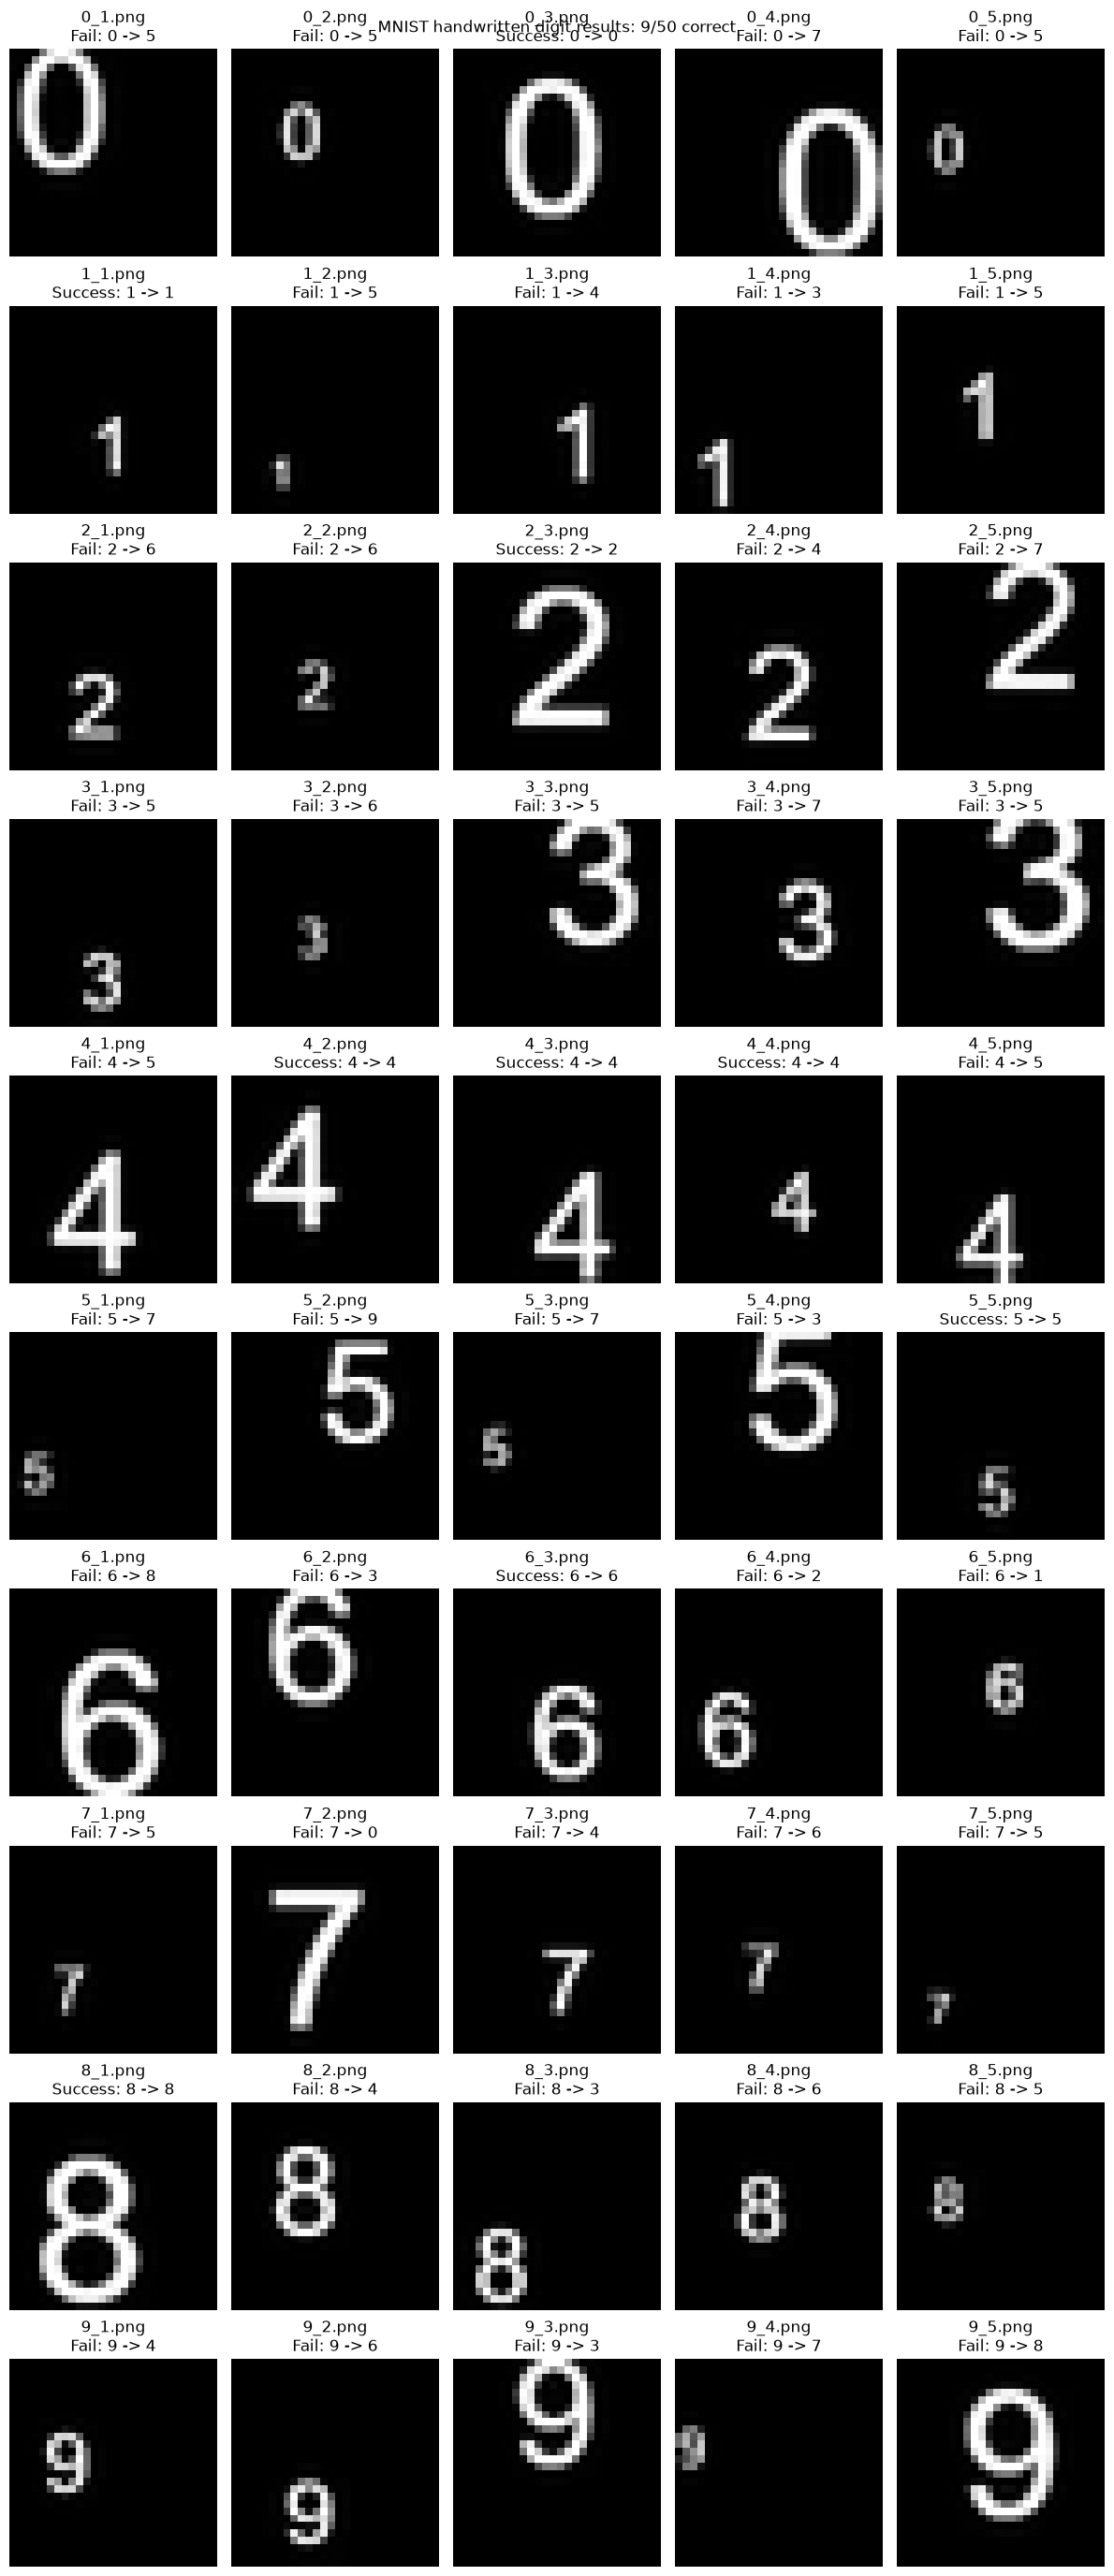

Accuracy: 9/50


In [5]:
# Evaluate all handwritten digit images in A_05/dataset/
results = evaluate_dataset("dataset")
print(f"Accuracy: {sum(results)}/{len(results)}")